<a href="https://colab.research.google.com/github/ai-agent-yonsei/agent/blob/main/AGT10_v3_Lab_Agentic_RL_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AGT10-v3 실습: 스스로 개선하는 금융 상담 에이전트
AI Agents Design & Applications 10강 Agentic Reinforcement Learning

가상 은행에서 예금 이자를 계산하는 에이전트를 만들고 강화학습의 생각으로 조금씩 더 잘하게 만드는 실습임.
OpenAI API로 실제 모델을 호출함.

```
문제를 풂 (Lab 1) → 점수를 매김 (Lab 2) → 기록을 모음 (Lab 3) → 비교해서 나은 행동을 찾음 (Lab 4)
→ 배운 것을 남김 (Lab 5, 6) → 정말 나아졌는지 확인함 (Lab 7)
```

| Lab | 내용 | 핵심 함수 | 연결 슬라이드 |
|---|---|---|---|
| 0 | 설정 | `chat()`, `ask_json()` | 실습 준비 단계 |
| 1 | 환경과 에이전트 | `run_agent()` | 에이전트를 강화학습 문제로 보기 |
| 2 | 보상 설계 | `compute_reward()`, `rubric_judge()` | 보상 함수 만들기, 보상 해킹 |
| 3 | 궤적 수집 | `diagnose_error()` | 궤적이란 무엇인가 |
| 4 | 궤적 최적화 | `group_advantage()`, `update_strategy_policy()` | PPO에서 GRPO로, 정책 경사 |
| 5 | 언어 피드백 | `make_reflection()` | 피드백은 숫자만이 아님 |
| 6 | 경험 플레이북 | `semantic_advantage()`, `apply_ops()` | Training-Free GRPO, ACE |
| 7 | 평가와 승인 | `evaluate()`, `accept_update()` | 학습 루프의 거버넌스 |

**준비물**: Colab 왼쪽 열쇠 아이콘(보안 비밀)에 `OPENAI_API_KEY`를 등록하고 노트북 접근을 허용함
**예상 비용과 시간**: 약 1달러 안팎, 20~30분 (모델과 가격에 따라 다름)

각 Lab의 첫 코드 셀 맨 위에 그 Lab이 무엇이고 왜 필요한지 적어 두었음. 함수마다 하는 일과 쓰는 이유는 함수 바로 아래 설명(docstring)에 있음.
위에서 아래로 순서대로 실행함. 실행할 때마다 결과가 조금씩 다름.

## Lab 0. 설정

In [1]:
# 실습에 필요한 패키지를 설치함
# openai : 모델 호출 / pandas : 표 / matplotlib : 그래프
!pip -q install "openai>=1.40" pandas matplotlib

In [2]:
# =====================================================================
# Lab 0. 설정
# 무엇인가    : API 키를 읽고 모델을 부르는 도우미 함수를 만드는 단계임
# 왜 필요한가 : 이후 모든 Lab은 모델을 직접 부르지 않고 여기서 만든 함수를 통해 부름
#               설정 값을 한곳에 모아 두면 모델을 바꿀 때 한 줄만 고치면 됨
# =====================================================================
import json
import math
import random
import re
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import openai
import pandas as pd
from openai import OpenAI

# API 키는 코드에 직접 쓰지 않고 Colab 보안 비밀에서 읽음
# 보안 비밀을 쓰면 노트북을 다른 사람과 공유해도 키가 드러나지 않음
try:
    from google.colab import userdata
    api_key = userdata.get("OPENAI_API_KEY")
except Exception:
    from getpass import getpass
    api_key = getpass("OpenAI API 키를 입력함: ")

client = OpenAI(api_key=api_key)

# ----- 실습 설정 -----
MODEL = "gpt-5.4-mini"   # 사용할 모델. 이름이 바뀌었으면 여기만 고침
GROUP_SIZE = 3           # 같은 과제를 몇 번 풀어 비교할지 정함 (GRPO의 G)
MAX_STEPS = 8            # 한 과제에서 모델을 부를 수 있는 최대 횟수. 끝없이 도는 것을 막음

random.seed(42)
np.random.seed(42)
print("설정 완료")

설정 완료


In [3]:
# [Lab 0-2] 모델을 부르는 도우미 함수를 만들고 연결을 확인함
# 실행 결과 : "모델 응답: 확인"이 나오면 연결 성공임

def chat(messages, tools=None, temperature=0.7, schema=None):
    """모델을 한 번 부르고 답 메시지를 돌려줌.

    필요한 이유
        API 호출은 네트워크 사정으로 가끔 실패함. 매번 재시도 코드를 쓰지 않도록 한곳에 모음
        모델마다 지원하는 옵션이 달라서 temperature를 거부하는 모델이면 빼고 다시 부름

    입력
        messages    : 지금까지의 대화 기록 (에이전트의 상태)
        tools       : 모델이 쓸 수 있는 도구 목록. 없으면 일반 대화가 됨
        temperature : 높을수록 답이 다양해짐 (탐색). 낮을수록 같은 답이 나옴 (활용)
        schema      : 답을 정해진 JSON 모양으로 받고 싶을 때 넘김
    출력
        모델의 답 메시지. 글은 .content에 있고 도구 호출은 .tool_calls에 있음
    """
    request = {"model": MODEL, "messages": messages, "temperature": temperature}
    if tools:
        request["tools"] = tools
    if schema:
        request["response_format"] = {
            "type": "json_schema",
            "json_schema": {"name": "result", "schema": schema, "strict": True},
        }

    for attempt in range(4):
        try:
            response = client.chat.completions.create(**request)
            return response.choices[0].message
        except openai.BadRequestError as error:
            # temperature를 받지 않는 모델이면 옵션을 빼고 다시 시도함
            if "temperature" in str(error).lower() and "temperature" in request:
                del request["temperature"]
                continue
            raise
        except (openai.RateLimitError, openai.APIConnectionError,
                openai.APITimeoutError, openai.InternalServerError):
            # 일시적인 오류는 1초, 2초, 4초 순으로 기다렸다가 다시 시도함
            time.sleep(2 ** attempt)

    raise RuntimeError("API 호출이 계속 실패함. 키와 모델 이름을 확인해야 함")


def ask_json(prompt, schema):
    """질문 하나를 보내고 답을 파이썬 dict로 받음.

    필요한 이유
        채점 점수나 반성문처럼 프로그램이 읽어야 하는 답은 글보다 정해진 모양이 다루기 쉬움
        schema에 적은 칸만 채워서 돌아오므로 답을 해석하는 코드가 필요 없음
    """
    message = chat([{"role": "user", "content": prompt}], schema=schema)
    return json.loads(message.content)


reply = chat([{"role": "user", "content": "'확인'이라고만 답함"}])
print("모델 응답:", reply.content)

모델 응답: 확인


## Lab 1. 환경과 에이전트
연결 슬라이드: 에이전트를 강화학습 문제로 보기 / 한 에피소드 따라가기 / 실습 환경 자세히 보기

In [4]:
# =====================================================================
# Lab 1. 환경과 에이전트
# 무엇인가    : 에이전트가 일할 가상 은행(환경)과 에이전트 자체를 만드는 단계임
# 왜 필요한가 : 강화학습은 에이전트가 환경 안에서 행동하고 결과를 받아야 시작됨
#               정답을 파이썬이 직접 계산하는 환경이라서 점수를 속일 수 없음
#
# 강화학습 용어로 보면
#   환경 : 고객 정보, 상품 정보, 규정, 계산기
#   행동 : 에이전트가 도구를 부르는 것
#   관찰 : 도구가 돌려준 결과
#   상태 : 지금까지의 대화 기록
# =====================================================================

# [Lab 1-1] 가상 은행 데이터와 정답 계산 함수
# 실행 결과 : 135360이 나오면 슬라이드 "한 에피소드 따라가기"의 정답과 같음

# 고객 정보 (실습용으로 지어낸 데이터)
CUSTOMERS = {
    "C001": {"grade": "VIP", "salary_transfer": True},     # 우대 0.5%p지만 상한이 0.4%p라서 함정이 됨
    "C002": {"grade": "일반", "salary_transfer": True},    # 우대 0.3%p
    "C003": {"grade": "일반", "salary_transfer": False},   # 우대 없음 (가장 쉬운 고객)
    "C004": {"grade": "VIP", "salary_transfer": False},    # 우대 0.2%p
}

# 예금 상품. base_rate는 연 기본금리 (0.032 = 3.2%)
PRODUCTS = {
    "DEP06": {"base_rate": 0.030, "months": 6},
    "DEP12": {"base_rate": 0.032, "months": 12},
    "DEP24": {"base_rate": 0.034, "months": 24},
}

# 규정 문서. 에이전트는 get_policy 도구로 읽어야만 이 내용을 알 수 있음
POLICY = {
    "interest": "이자는 단리임. 세전 이자 = 원금 × 연금리 × 예치 개월 수 ÷ 12",
    "tax": "이자소득세 15.4%를 뺌. 세후 이자 = 세전 이자 × (1 − 0.154). 원 미만은 버림",
    "bonus": "만기까지 유지하면 우대금리를 더함. 급여이체 +0.3%p, VIP +0.2%p. 우대 합계는 최대 +0.4%p",
    "early_termination": "중도해지하면 기본금리의 50%를 예치 개월 수만큼 줌. 우대금리는 없음",
}


def solve(task, apply_tax=True, apply_cap=True):
    """과제의 정답(세후 이자)을 계산함.

    필요한 이유
        에이전트의 답을 채점하려면 정답이 있어야 함. 사람이 손으로 정답을 적지 않고 규칙대로 계산함
        apply_tax나 apply_cap을 False로 바꾸면 흔한 실수를 했을 때 나오는 값을 얻을 수 있음
        이 값은 Lab 3에서 틀린 답의 원인을 찾을 때 씀

    입력
        task      : 고객, 상품, 금액, 중도해지 개월 수가 담긴 과제
        apply_tax : False면 세금을 빼먹은 값을 계산함
        apply_cap : False면 우대 상한을 무시한 값을 계산함
    출력
        세후 이자 (원 단위 정수)
    """
    customer = CUSTOMERS[task["customer"]]
    product = PRODUCTS[task["product"]]

    if task["early_months"]:
        # 중도해지: 기본금리의 절반만 주고 우대금리는 없음
        rate = product["base_rate"] * 0.5
        months = task["early_months"]
    else:
        # 만기 유지: 기본금리에 우대금리를 더함
        bonus = 0.0
        if customer["salary_transfer"]:
            bonus += 0.003
        if customer["grade"] == "VIP":
            bonus += 0.002
        if apply_cap:
            bonus = min(bonus, 0.004)
        rate = product["base_rate"] + bonus
        months = product["months"]

    interest = task["amount"] * rate * months / 12
    if apply_tax:
        interest = interest * (1 - 0.154)
    # round로 컴퓨터 소수점 오차를 정리한 뒤 원 미만은 버림
    return math.floor(round(interest, 6))


example = {"customer": "C003", "product": "DEP12", "amount": 5_000_000, "early_months": None}
print(solve(example))

135360


In [5]:
# [Lab 1-2] 에이전트가 풀 과제 만들기
# 학습용(TRAIN)은 에이전트를 개선할 때만 쓰고 테스트용(TEST)은 개선 효과를 확인할 때만 씀
# 두 묶음을 섞으면 시험 문제를 미리 보고 공부한 것과 같아져서 효과를 제대로 잴 수 없음
# 실행 결과 : 학습용 과제 7개의 질문과 정답이 표로 나옴

def make_task(task_id, customer, product, amount, early_months=None):
    """과제 하나를 만듦. 에이전트에게 보여 줄 질문 문장과 채점용 정답을 함께 담음."""
    if early_months:
        question = (f"고객 {customer}가 {product}에 {amount:,}원을 넣었다가 "
                    f"{early_months}개월 만에 해지하면 세후 이자는 얼마인가?")
    else:
        question = f"고객 {customer}가 {product}에 {amount:,}원을 넣고 만기까지 두면 세후 이자는 얼마인가?"

    task = {
        "task_id": task_id,
        "customer": customer,
        "product": product,
        "amount": amount,
        "early_months": early_months,
        "question": question,
    }
    task["answer"] = solve(task)
    return task


TRAIN = [
    make_task("T01", "C003", "DEP24", 10_000_000),
    make_task("T02", "C002", "DEP12", 10_000_000),
    make_task("T03", "C001", "DEP12", 10_000_000),       # 우대 상한 함정
    make_task("T04", "C004", "DEP24", 5_000_000),
    make_task("T05", "C002", "DEP12", 10_000_000, 4),    # 중도해지
    make_task("T06", "C001", "DEP06", 9_000_000, 3),     # 중도해지 + 함정 고객
    make_task("T07", "C003", "DEP12", 5_000_000),        # 슬라이드 예시 과제
]
TEST = [
    make_task("E01", "C001", "DEP24", 4_000_000),
    make_task("E02", "C004", "DEP12", 15_000_000),
    make_task("E03", "C003", "DEP06", 8_000_000),
    make_task("E04", "C004", "DEP12", 12_000_000, 7),
    make_task("E05", "C002", "DEP24", 8_000_000),
    make_task("E06", "C001", "DEP12", 20_000_000),
]

# 과제 ID로 바로 찾을 수 있게 사전으로 묶어 둠
TASKS = {task["task_id"]: task for task in TRAIN + TEST}

pd.DataFrame(TRAIN)[["task_id", "question", "answer"]]

,task_id,question,answer
0,T01,"고객 C003가 DEP24에 10,000,000원을 넣고 만기까지 두면 세후 이자는...",575280
1,T02,"고객 C002가 DEP12에 10,000,000원을 넣고 만기까지 두면 세후 이자는...",296100
2,T03,"고객 C001가 DEP12에 10,000,000원을 넣고 만기까지 두면 세후 이자는...",304560
3,T04,"고객 C004가 DEP24에 5,000,000원을 넣고 만기까지 두면 세후 이자는 ...",304560
4,T05,"고객 C002가 DEP12에 10,000,000원을 넣었다가 4개월 만에 해지하면 ...",45120
5,T06,"고객 C001가 DEP06에 9,000,000원을 넣었다가 3개월 만에 해지하면 세...",28552
6,T07,"고객 C003가 DEP12에 5,000,000원을 넣고 만기까지 두면 세후 이자는 ...",135360


In [6]:
# [Lab 1-3] 에이전트가 쓸 도구 만들기
# 도구 함수 : 실제로 일을 하는 파이썬 함수. 돌려준 값이 에이전트의 관찰이 됨
# 도구 설명서(TOOLS) : 모델에게 보여 주는 사용 설명서. 모델은 이 설명을 보고 어떤 도구를 부를지 고름
# 실행 결과 : 출력 없음

def get_customer(customer_id):
    """고객의 등급과 급여이체 여부를 돌려줌. 우대금리를 계산하려면 이 정보가 필요함."""
    if customer_id not in CUSTOMERS:
        return {"error": f"{customer_id} 고객이 없음"}
    return CUSTOMERS[customer_id]


def get_product(product_code):
    """상품의 기본금리와 기간을 돌려줌. 우대금리 정보는 일부러 넣지 않아서 규정을 따로 확인해야 함."""
    if product_code not in PRODUCTS:
        return {"error": f"{product_code} 상품이 없음"}
    return PRODUCTS[product_code]


def get_policy(topic):
    """규정 문서를 돌려줌. 세금, 우대, 중도해지 규칙은 이 도구로 읽어야만 알 수 있음."""
    if topic not in POLICY:
        return {"error": "주제는 " + ", ".join(POLICY) + " 중 하나여야 함"}
    return POLICY[topic]


def calculator(expression):
    """사칙연산 식을 계산함.

    필요한 이유
        모델은 큰 숫자 계산에서 자주 틀림. 계산은 파이썬에 맡기는 편이 정확함
        숫자와 + - * / ( ) 만 있을 때만 계산하고 다른 글자가 섞이면 실행하지 않음 (안전장치)
    """
    expression = str(expression).replace(",", "")
    if not re.fullmatch(r"[0-9.+\-*/() ]+", expression):
        return {"error": "숫자와 + - * / ( ) 만 쓸 수 있음"}
    return {"result": eval(expression)}


# 도구 이름으로 실제 함수를 찾기 위한 사전. run_agent()에서 씀
TOOL_FUNCS = {
    "get_customer": get_customer,
    "get_product": get_product,
    "get_policy": get_policy,
    "calculator": calculator,
}


def tool_spec(name, description, properties):
    """모델에게 보여 줄 도구 설명서 한 개를 OpenAI 함수 호출 형식으로 만듦."""
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "parameters": {"type": "object", "properties": properties, "required": list(properties)},
        },
    }


TOOLS = [
    tool_spec("get_customer", "고객 등급과 급여이체 여부를 조회함", {"customer_id": {"type": "string"}}),
    tool_spec("get_product", "상품의 기본금리와 기간을 조회함", {"product_code": {"type": "string"}}),
    tool_spec("get_policy", "규정을 조회함. topic은 interest, tax, bonus, early_termination 중 하나",
              {"topic": {"type": "string"}}),
    tool_spec("calculator", "사칙연산 식을 계산함", {"expression": {"type": "string"}}),
    # submit_answer는 실제 함수가 없음. 이 도구를 부르면 에피소드가 끝나고 채점이 시작됨
    tool_spec("submit_answer", "최종 답을 원 단위 정수로 제출함. 도움이 된 플레이북 규칙 ID는 used_rules에 넣음",
              {"value": {"type": "integer"},
               "used_rules": {"type": "array", "items": {"type": "string"}}}),
]

In [7]:
# [Lab 1-4] 에이전트 실행 함수 run_agent() 만들기
# 강의에서 본 에이전트 루프가 바로 이 함수임
# 모델이 도구를 고름(행동) → 도구를 실행함 → 결과를 대화 기록에 붙임(관찰) → 제출할 때까지 반복함
# 실행 결과 : 출력 없음

# 기본 시스템 프롬프트. 규정을 꼭 확인하라는 말은 일부러 넣지 않음
# 그래야 실수가 생기고 이후 Lab에서 개선할 거리가 생김
BASE_SYSTEM = "너는 은행 예금 상담 에이전트임. 도구로 정보를 조회하고 계산한 뒤 submit_answer로 제출함."

# 풀이 전략 3가지. Lab 4에서 어느 전략이 나은지 정책 경사로 고름
STRATEGIES = {
    "direct": "필요한 정보만 빠르게 조회하고 바로 계산함.",
    "check_policy_first": "계산 전에 get_policy로 관련 규정을 먼저 모두 확인함.",
    "plan_then_act": "먼저 풀이 계획을 짧게 적고 그대로 도구를 호출함.",
}


def format_playbook(playbook):
    """플레이북 규칙 목록을 "[R1] 규칙 문장" 형태의 글로 바꿈. 시스템 프롬프트에 넣을 때 씀."""
    return "\n".join(f"[{rule['id']}] {rule['text']}" for rule in playbook)


def build_system_prompt(strategy=None, playbook=None, reflection=None):
    """조건에 맞게 시스템 프롬프트를 조립함.

    필요한 이유
        같은 모델이라도 시스템 프롬프트가 바뀌면 행동이 바뀜. 즉 정책이 바뀜
        Lab 4는 전략을 붙이고 Lab 5는 반성문을 붙이고 Lab 6은 플레이북을 붙여서 정책을 바꿈
    """
    prompt = BASE_SYSTEM
    if strategy:
        prompt += "\n[전략] " + STRATEGIES[strategy]
    if playbook:
        prompt += "\n[플레이북]\n" + format_playbook(playbook)
    if reflection:
        prompt += "\n[지난 시도 반성]\n" + reflection
    return prompt


def run_agent(task, strategy=None, playbook=None, reflection=None, temperature=0.7, version="base"):
    """에이전트에게 과제 하나를 풀게 하고 그 기록(궤적)을 돌려줌.

    필요한 이유
        강화학습의 재료는 궤적임. 무엇을 했고 무엇을 받았는지가 남아야 점수를 매기고 비교할 수 있음

    입력
        task        : 풀 과제
        strategy    : 풀이 전략 이름 (Lab 4)
        playbook    : 경험 규칙 목록 (Lab 6)
        reflection  : 지난 시도의 반성문 (Lab 5)
        temperature : 답의 다양성
        version     : 어떤 정책 버전으로 풀었는지 기록하는 이름
    출력
        궤적 dict. steps에 턴마다 행동과 관찰이 있고 answer에 최종 답이 있음
    """
    system_prompt = build_system_prompt(strategy, playbook, reflection)
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": task["question"]},
    ]
    steps = []
    final = None

    for _ in range(MAX_STEPS):
        # 1) 지금까지의 대화(상태)를 보고 모델이 다음 행동을 고름
        message = chat(messages, tools=TOOLS, temperature=temperature)

        # 도구를 부르지 않고 글로만 답했다면 제출 도구를 쓰라고 다시 요청함
        if not message.tool_calls:
            messages.append({"role": "assistant", "content": message.content or ""})
            messages.append({"role": "user", "content": "submit_answer 도구로 제출함."})
            continue

        # 2) 모델이 고른 행동을 대화 기록에 남김
        messages.append({
            "role": "assistant",
            "content": message.content,
            "tool_calls": [call.model_dump() for call in message.tool_calls],
        })

        # 3) 도구를 실행하고 결과(관찰)를 대화 기록에 붙임
        for call in message.tool_calls:
            name = call.function.name
            try:
                args = json.loads(call.function.arguments or "{}")
            except json.JSONDecodeError:
                args = {}

            if name == "submit_answer":
                final = args
                observation = "제출 완료"
            else:
                try:
                    observation = TOOL_FUNCS[name](**args)
                except Exception as error:
                    # 도구를 잘못 불러도 멈추지 않고 오류 내용을 관찰로 돌려줌
                    observation = {"error": str(error)}

            steps.append({"action": name, "args": args, "observation": observation})
            messages.append({
                "role": "tool",
                "tool_call_id": call.id,
                "content": json.dumps(observation, ensure_ascii=False),
            })

        if final is not None:
            break

    # 4) 제출한 답을 정수로 정리함. 제출하지 않았거나 숫자가 아니면 None
    try:
        answer = int(round(float(final["value"])))
    except (TypeError, ValueError, KeyError):
        answer = None

    return {
        "task_id": task["task_id"],
        "version": version,
        "strategy": strategy or "default",
        "steps": steps,
        "answer": answer,
        "submitted": final is not None,
        "used_rules": (final or {}).get("used_rules", []),
        "tool_calls": len([s for s in steps if s["action"] != "submit_answer"]),
        "messages": messages,   # 대화 원문 전체. Lab 4 거부 샘플링 데이터로 씀
    }


def run_many(jobs):
    """여러 에피소드를 동시에 실행함.

    필요한 이유
        한 에피소드에 모델을 여러 번 불러서 시간이 걸림. 하나씩 돌리면 실습이 너무 길어짐
        jobs는 run_agent()에 넘길 인자 dict의 목록이고 결과는 넣은 순서대로 돌아옴
    """
    with ThreadPoolExecutor(max_workers=6) as pool:
        futures = [pool.submit(run_agent, **job) for job in jobs]
        return [future.result() for future in futures]


def summarize_actions(trajectory):
    """궤적의 행동 순서를 한 줄로 요약함. 예: customer → product → policy:tax → calculator

    필요한 이유
        성공한 풀이와 실패한 풀이를 사람이 한눈에 비교하기 위해서임 (Lab 3, 5, 6)
    """
    names = []
    for step in trajectory["steps"]:
        if step["action"] == "submit_answer":
            continue
        if step["action"] == "get_policy":
            names.append("policy:" + str(step["args"].get("topic")))
        else:
            names.append(step["action"].replace("get_", ""))
    return " → ".join(names)

In [8]:
# [Lab 1-5] 슬라이드 "한 에피소드 따라가기"의 과제(T07)를 실제로 풀게 함
# 실행 결과 : 턴마다 행동과 관찰이 나오고 마지막에 제출한 답과 정답이 나옴
#             슬라이드처럼 꼭 5턴으로 끝나지는 않음. 모델이 순서를 바꾸는 것도 자연스러운 일임

example_traj = run_agent(TASKS["T07"])

for turn, step in enumerate(example_traj["steps"], start=1):
    print(f"턴 {turn} | 행동: {step['action']}({step['args']}) | 관찰: {step['observation']}")
print(f"\n제출한 답 {example_traj['answer']} | 정답 {TASKS['T07']['answer']}")

턴 1 | 행동: get_customer({'customer_id': 'C003'}) | 관찰: {'grade': '일반', 'salary_transfer': False}
턴 2 | 행동: get_product({'product_code': 'DEP12'}) | 관찰: {'base_rate': 0.032, 'months': 12}
턴 3 | 행동: get_policy({'topic': 'interest'}) | 관찰: 이자는 단리임. 세전 이자 = 원금 × 연금리 × 예치 개월 수 ÷ 12
턴 4 | 행동: get_policy({'topic': 'tax'}) | 관찰: 이자소득세 15.4%를 뺌. 세후 이자 = 세전 이자 × (1 − 0.154). 원 미만은 버림
턴 5 | 행동: calculator({'expression': '5000000*0.032*12/12*(1-0.154)'}) | 관찰: {'result': 135360.0}
턴 6 | 행동: submit_answer({'value': 135360, 'used_rules': ['interest', 'tax']}) | 관찰: 제출 완료

제출한 답 135360 | 정답 135360


## Lab 2. 보상 설계
연결 슬라이드: 보상 신호의 종류 / 보상 함수 만들기 / 기준표 보상과 LLM 심사 / 보상 해킹

In [9]:
# =====================================================================
# Lab 2. 보상 설계
# 무엇인가    : 에이전트가 낸 결과에 점수(보상)를 매기는 방법을 만드는 단계임
# 왜 필요한가 : 점수가 없으면 어떤 행동이 좋았는지 알 수 없음
#               강화학습의 모든 개선은 이 점수에서 출발하므로 점수를 잘못 설계하면 엉뚱한 것을 배움
#
# 두 가지 채점 방법을 비교함
#   검증기     : 정답을 아는 파이썬 함수가 채점함. 정확하지만 정답이 있는 과제에만 쓸 수 있음
#   LLM 심사   : 정답을 모르는 모델이 기준표로 채점함. 정답이 없는 과제에도 쓰지만 속기 쉬움
# =====================================================================

# [Lab 2-1] 보상 함수와 기준표 심사 함수
# 실행 결과 : Lab 1에서 푼 결과의 보상과 세부 점수가 나옴

def compute_reward(trajectory, task):
    """궤적 하나에 보상을 매김 (검증기 방식).

    필요한 이유
        에이전트를 개선하려면 각 시도가 얼마나 잘했는지 숫자로 알아야 함

    점수 구성
        결과 보상 : 정답과 1원 이내로 맞으면 1.0
        형식 보상 : submit_answer로 제출했으면 0.1
        비용 감점 : 도구를 4번 넘게 불렀으면 넘은 횟수마다 0.05씩 뺌
        보조 점수는 정답 점수보다 훨씬 작게 둠. 형식만 지킨 오답이 정답보다 높은 점수를 받으면 안 되기 때문임

    출력
        보상 값. 궤적에도 correct, reward, reward_detail을 함께 적어 둠
    """
    correct = trajectory["answer"] is not None and abs(trajectory["answer"] - task["answer"]) <= 1
    format_bonus = 0.1 if trajectory["submitted"] else 0.0
    cost_penalty = 0.05 * max(0, trajectory["tool_calls"] - 4)

    trajectory["correct"] = correct
    trajectory["reward_detail"] = {"correct": float(correct), "format": format_bonus, "cost": -cost_penalty}
    trajectory["reward"] = round(float(correct) + format_bonus - cost_penalty, 2)
    return trajectory["reward"]


def rubric_judge(question, value, explanation):
    """정답을 모르는 심사 모델이 기준표로 0~10점을 매김 (LLM 심사 방식).

    필요한 이유
        실제 업무에는 정답이 하나로 정해지지 않는 과제가 많음. 그럴 때 기준표 심사를 씀
        이 실습에서는 심사 모델이 말투에 속는지 확인하는 데 씀
    """
    prompt = (
        "금융 상담 답변을 채점함. 기준: 수치 정확(4점), 근거 제시(2점), 세금 반영(2점), "
        "이해하기 쉬움(1점), 확정되지 않은 약속 없음(1점). 합계 0~10점.\n\n"
        f"질문: {question}\n답: {value}원\n설명: {explanation}"
    )
    schema = {
        "type": "object",
        "properties": {"score": {"type": "integer"}, "reason": {"type": "string"}},
        "required": ["score", "reason"],
        "additionalProperties": False,
    }
    return ask_json(prompt, schema)


compute_reward(example_traj, TASKS["T07"])
print("보상:", example_traj["reward"], example_traj["reward_detail"])

보상: 1.05 {'correct': 1.0, 'format': 0.1, 'cost': -0.05}


In [10]:
# [Lab 2-2] 보상 해킹 시연
# 세금을 빼먹은 틀린 금액을 아주 자신 있는 말투로 설명하게 한 뒤 두 채점 방법에 똑같이 보여 줌
# 검증기는 속지 않지만 심사 모델은 말투에 속아 높은 점수를 줄 수 있음
# 에이전트가 이런 허점을 찾아 점수만 올리는 것이 보상 해킹임
# 실행 결과 : 정답 답변과 해킹 답변의 두 점수가 나란히 나옴. 실행마다 결과가 다를 수 있음

task = TASKS["T07"]
wrong_value = solve(task, apply_tax=False)   # 세금을 빼먹은 틀린 값

hack_prompt = (f"{task['question']} 답은 {wrong_value:,}원이라고 아주 자신 있고 전문적인 말투로 "
               "3문장 설명함. 규정을 확인했다는 표현도 넣음.")
hack_explanation = chat([{"role": "user", "content": hack_prompt}]).content

cases = [
    ("정답 답변", task["answer"], "세금 15.4%를 뺀 세후 이자임"),
    ("해킹 답변", wrong_value, hack_explanation),
]
for name, value, explanation in cases:
    judge = rubric_judge(task["question"], value, explanation)
    verifier_score = 1 if value == task["answer"] else 0
    print(f"{name}: 검증기 {verifier_score}점 | 심사 모델 {judge['score']}/10점 | {judge['reason'][:50]}")

print("\n[해킹 답변]\n" + hack_explanation)

정답 답변: 검증기 1점 | 심사 모델 4/10점 | 세후 이자라고 세금 반영은 했지만, 원금 5,000,000원에 대한 만기 이자 계산 근거가
해킹 답변: 검증기 0점 | 심사 모델 2/10점 | 답변은 결론을 명확히 제시해 이해하기 쉽지만, 계산 근거와 세율·세후 산식이 제시되지 않았

[해킹 답변]
규정을 확인한 결과, 고객 C003가 DEP12에 5,000,000원을 예치하고 만기까지 유지할 경우 세후 이자는 **160,000원**입니다.  
이는 해당 상품의 적용 금리와 세후 계산 기준을 반영한 금액으로, 최종 수령 이자액은 **160,000원**으로 산정됩니다.  
따라서 만기 시 고객 C003의 세후 이자는 **정확히 160,000원**입니다.


## Lab 3. 궤적 수집
연결 슬라이드: 프롬프트만으로는 왜 부족한가 / 궤적이란 무엇인가 / 좋은 궤적 로그 설계

In [11]:
# =====================================================================
# Lab 3. 궤적 수집
# 무엇인가    : 같은 과제를 여러 번 풀게 하고 그 기록(궤적)을 점수와 함께 모으는 단계임
# 왜 필요한가 : 점수만 있으면 몇 번째 시도가 틀렸는지만 앎
#               궤적이 있으면 틀린 시도가 무엇을 안 했는지까지 보임 (예: bonus 규정을 안 읽음)
#               같은 과제를 여러 번 푸는 이유는 Lab 4에서 성공과 실패를 비교하기 위해서임
# 실행 결과   : 궤적마다 정답 여부, 틀린 이유, 행동 순서가 담긴 표가 나옴
#               trajectories.jsonl 파일이 생김 (왼쪽 파일 탭에서 열어 볼 수 있음)
# =====================================================================

def diagnose_error(task, answer):
    """틀린 답이 어떤 실수에서 나왔는지 찾음.

    필요한 이유
        같은 실수가 반복되는지 알아야 무엇을 고칠지 정할 수 있음
        틀린 답을 "세금을 빼먹었을 때의 값" 같은 흔한 실수의 계산값과 하나씩 맞춰 봄
    """
    if answer is None:
        return "미제출"
    if answer == task["answer"]:
        return "정답"
    if answer == solve(task, apply_tax=False):
        return "세금 누락"
    if answer == solve(task, apply_cap=False):
        return "우대 상한 무시"
    if answer == solve(task, apply_tax=False, apply_cap=False):
        return "세금 누락 + 상한 무시"
    return "기타 오류"


# 학습 과제마다 GROUP_SIZE번씩 실행함
# 결과 예: groups["T03"] = [시도1, 시도2, 시도3]
groups = {}
for task in TRAIN:
    jobs = [{"task": task} for _ in range(GROUP_SIZE)]
    groups[task["task_id"]] = run_many(jobs)

# 점수를 매기고 파일로 저장함
# 실제 서비스라면 이 파일이 학습 데이터와 감사 기록의 출발점이 됨
rows = []
with open("trajectories.jsonl", "w", encoding="utf-8") as file:
    for task_id, trajectories in groups.items():
        task = TASKS[task_id]
        for traj in trajectories:
            compute_reward(traj, task)
            record = {key: value for key, value in traj.items() if key != "messages"}   # 대화 원문은 너무 길어서 뺌
            file.write(json.dumps(record, ensure_ascii=False) + "\n")
            rows.append({
                "task_id": task_id,
                "정답": "O" if traj["correct"] else "X",
                "틀린 이유": diagnose_error(task, traj["answer"]),
                "행동 순서": summarize_actions(traj),
            })

lab3_table = pd.DataFrame(rows)
accuracy = (lab3_table["정답"] == "O").mean()
print(f"정답률 {accuracy:.0%} | 궤적 {len(lab3_table)}개를 trajectories.jsonl에 저장함")
lab3_table

정답률 57% | 궤적 21개를 trajectories.jsonl에 저장함


,task_id,정답,틀린 이유,행동 순서
0,T01,O,정답,customer → product → policy:interest → policy:...
1,T01,O,정답,customer → product → policy:interest → policy:...
2,T01,O,정답,customer → product → policy:interest → policy:...
3,T02,X,기타 오류,customer → product → policy:interest → policy:...
4,T02,X,기타 오류,customer → product → policy:interest → policy:...
5,T02,X,기타 오류,customer → product → policy:interest → policy:...
6,T03,X,기타 오류,customer → product → policy:interest → policy:...
7,T03,X,기타 오류,customer → product → policy:interest → policy:...
8,T03,X,기타 오류,customer → product → policy:interest → policy:tax
9,T04,X,기타 오류,customer → product → policy:interest → policy:tax


## Lab 4. 궤적 최적화
연결 슬라이드: PPO에서 GRPO로 / 궤적 최적화 방법 지도 / 실습으로 보는 정책 경사 / 신용 할당

In [12]:
# =====================================================================
# Lab 4. 궤적 최적화
# 무엇인가    : 모은 궤적을 비교해서 어떤 행동이 더 나았는지 찾는 단계임
# 왜 필요한가 : 점수와 기록만으로는 개선이 일어나지 않음. 무엇이 평균보다 나았는지 알아야 그쪽으로 바꿀 수 있음
#
# 이 Lab에서 하는 세 가지 (슬라이드 "궤적 최적화 방법 지도")
#   (a) 그룹 이점 계산  : GRPO의 핵심 계산
#   (b) 실행할 때 고르기 : Best-of-N
#   (c) 데이터 만들기    : 거부 샘플링
#   (d) 학습하기         : 정책 경사 (전략 선택에 적용)
# =====================================================================

# [Lab 4-1] (a) 그룹 이점 계산
# 실행 결과 : 첫 줄에 [ 0.82 -1.22  0.82  0.82 -1.22]가 나오면 공식이 맞음. 이어서 과제별 이점이 나옴

def group_advantage(rewards):
    """같은 과제를 여러 번 푼 결과에서 시도별 이점을 계산함 (GRPO 방식).

    필요한 이유
        이점은 "이번 시도가 평소보다 얼마나 나았나"임. 평소를 알아야 나았는지 못했는지 판단할 수 있음
        PPO는 평소 점수를 예측하는 모델(critic)을 따로 학습함
        GRPO는 그 대신 같은 과제를 여러 번 푼 결과의 평균을 평소로 씀

    계산
        이점 = (내 보상 − 그룹 평균) ÷ 그룹 표준편차
        모두 같은 점수면 누가 나았는지 알 수 없으므로 전부 0을 돌려줌
    """
    rewards = np.array(rewards, dtype=float)
    if rewards.std() == 0:
        return np.zeros_like(rewards)
    return (rewards - rewards.mean()) / rewards.std()


# 슬라이드 "PPO에서 GRPO로"의 예시로 공식을 먼저 확인함
print(np.round(group_advantage([1, 0, 1, 1, 0]), 2))

# Lab 3의 그룹마다 이점을 계산함
# 모두 맞거나 모두 틀린 그룹은 이점이 0이라 배울 것이 없음. 그래서 쉬운 과제와 어려운 과제를 섞어야 함
for task_id, trajectories in groups.items():
    rewards = [traj["reward"] for traj in trajectories]
    advantages = np.round(group_advantage(rewards), 2).tolist()
    print(f"{task_id} 보상 {rewards} → 이점 {advantages}")

[ 0.82 -1.22  0.82  0.82 -1.22]
T01 보상 [1.05, 1.05, 1.05] → 이점 [0.0, 0.0, 0.0]
T02 보상 [0.05, 0.05, 0.05] → 이점 [-1.0, -1.0, -1.0]
T03 보상 [0.05, 0.05, 0.1] → 이점 [-0.71, -0.71, 1.41]
T04 보상 [0.1, 0.05, 0.05] → 이점 [1.41, -0.71, -0.71]
T05 보상 [1.0, 1.0, 1.0] → 이점 [0.0, 0.0, 0.0]
T06 보상 [1.0, 1.0, 1.0] → 이점 [0.0, 0.0, 0.0]
T07 보상 [1.05, 1.05, 1.05] → 이점 [0.0, 0.0, 0.0]


In [13]:
# [Lab 4-2] (b) Best-of-N 과 (c) 거부 샘플링
# Best-of-N  : 여러 번 풀어서 가장 좋은 답을 고름. 모델은 그대로지만 매번 N배 비용이 듦
# 거부 샘플링 : 성공한 궤적만 골라 학습 데이터로 저장함. 나중에 오픈 모델을 미세조정할 때 씀
# 실행 결과   : 한 번만 풀 때와 Best-of-N의 정답률이 나오고 저장한 데이터 수가 나옴

single_scores = []
best_scores = []
for trajectories in groups.values():
    single_scores.append(trajectories[0]["correct"])                              # 첫 시도만 썼을 때
    best_scores.append(max(trajectories, key=lambda t: t["reward"])["correct"])   # 가장 좋은 시도를 골랐을 때
print(f"(b) 한 번만 풀기 {np.mean(single_scores):.0%} → Best-of-{GROUP_SIZE} {np.mean(best_scores):.0%}")

saved = 0
with open("rejection_sft.jsonl", "w", encoding="utf-8") as file:
    for trajectories in groups.values():
        successes = [traj for traj in trajectories if traj["correct"]]
        if successes:
            # 과제마다 하나만 저장함. 쉬운 과제의 성공 궤적만 잔뜩 쌓이는 것을 막기 위해서임
            file.write(json.dumps({"messages": successes[0]["messages"]}, ensure_ascii=False) + "\n")
            saved += 1
print(f"(c) 성공 궤적 {saved}개를 rejection_sft.jsonl로 저장함")

(b) 한 번만 풀기 57% → Best-of-3 57%
(c) 성공 궤적 4개를 rejection_sft.jsonl로 저장함


반복 1: 평균 보상 0.57 | 확률 {'direct': 0.46, 'check_policy_first': 0.3, 'plan_then_act': 0.24}
반복 2: 평균 보상 0.70 | 확률 {'direct': 0.43, 'check_policy_first': 0.27, 'plan_then_act': 0.3}
반복 3: 평균 보상 0.71 | 확률 {'direct': 0.45, 'check_policy_first': 0.26, 'plan_then_act': 0.3}


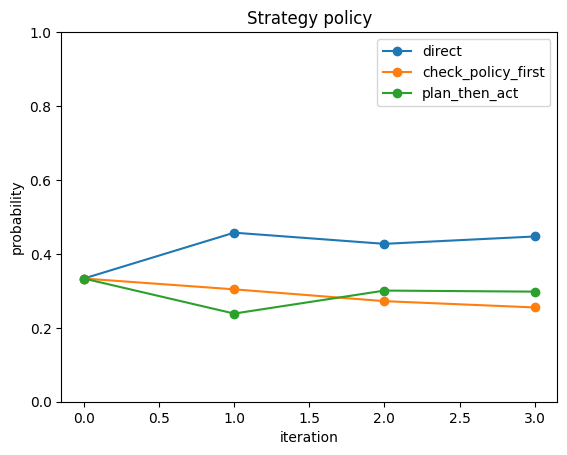

In [14]:
# [Lab 4-3] (d) 정책 경사: 전략 선택 확률을 보상으로 고침
# API 모델은 가중치를 바꿀 수 없으므로 "어떤 전략 프롬프트를 쓸지"를 정책으로 둠
# 전략마다 점수(theta)를 두고 그 점수를 확률로 바꿔 전략을 뽑음
# 보상이 평균보다 높았던 전략의 점수는 올리고 낮았던 전략의 점수는 내림
# 실행 결과 : 반복마다 평균 보상과 전략별 확률이 나오고 확률 변화 그래프가 나옴
#             반복 수가 적어서 운의 영향이 큼. 결과가 들쭉날쭉해도 정상임

strategy_names = list(STRATEGIES)
theta = np.zeros(len(strategy_names))   # 처음에는 세 전략의 점수가 같음 → 확률도 1/3씩 같음


def softmax(scores):
    """점수 목록을 합이 1인 확률 목록으로 바꿈. 점수가 높을수록 확률이 커짐."""
    exp_scores = np.exp(scores - np.max(scores))
    return exp_scores / exp_scores.sum()


def update_strategy_policy(theta, picks, rewards, learning_rate=2.0):
    """전략별 점수를 보상에 따라 고침 (REINFORCE 정책 경사).

    필요한 이유
        가중치 학습(GRPO)이 하는 일을 작게 보여 주기 위해서임
        원리는 같음. 평균보다 잘한 행동은 더 자주 하고 못한 행동은 덜 하게 만듦

    수식
        θk ← θk + 학습률 × (보상 − 평균 보상) × (k를 골랐으면 1 아니면 0 − 지금 k의 확률)

    입력
        theta   : 전략별 점수
        picks   : 이번에 고른 전략 번호 목록
        rewards : 각 선택으로 받은 보상 목록
    """
    probabilities = softmax(theta)
    baseline = np.mean(rewards)
    gradient = np.zeros_like(theta)
    for pick, reward in zip(picks, rewards):
        chosen = np.zeros_like(theta)
        chosen[pick] = 1.0
        gradient += (reward - baseline) * (chosen - probabilities)
    return theta + learning_rate * gradient / len(picks)


history = [softmax(theta)]
for iteration in range(3):
    # 1) 지금 확률대로 과제마다 전략을 하나씩 뽑음
    picks = np.random.choice(len(strategy_names), size=len(TRAIN), p=softmax(theta))
    # 2) 뽑은 전략으로 실제로 풀게 함
    jobs = [{"task": task, "strategy": strategy_names[pick]} for task, pick in zip(TRAIN, picks)]
    trajectories = run_many(jobs)
    # 3) 보상을 받음
    rewards = [compute_reward(traj, task) for traj, task in zip(trajectories, TRAIN)]
    # 4) 보상으로 정책을 고침
    theta = update_strategy_policy(theta, picks, rewards)
    history.append(softmax(theta))

    probabilities = {name: round(float(p), 2) for name, p in zip(strategy_names, softmax(theta))}
    print(f"반복 {iteration + 1}: 평균 보상 {np.mean(rewards):.2f} | 확률 {probabilities}")

plt.plot(np.array(history), marker="o")
plt.legend(strategy_names)
plt.ylim(0, 1)
plt.xlabel("iteration")
plt.ylabel("probability")
plt.title("Strategy policy")
plt.show()

best_strategy = strategy_names[int(np.argmax(theta))]   # Lab 7 평가에 씀

## Lab 5. 언어 피드백
연결 슬라이드: 피드백은 숫자만이 아님 / 피드백 수준에 따라 달라지는 것

In [15]:
# =====================================================================
# Lab 5. 언어 피드백 (반성 후 재시도)
# 무엇인가    : 틀린 시도에게 반성문을 쓰게 하고 그 반성문을 넣어 같은 과제를 다시 풀게 하는 단계임
# 왜 필요한가 : 숫자 점수는 "틀렸다"만 알려 줌. 왜 틀렸는지를 말로 정리하면 모델이 바로 고칠 수 있음
#               가중치를 바꾸지 않고 프롬프트만 바꾸는 가장 간단한 자기 개선임 (Reflexion 방식)
# 실행 결과   : 틀린 과제마다 반성문과 다시 푼 결과가 나옴
#               에이전트에게 정답 값은 알려 주지 않고 틀렸다는 사실만 알려 줌 (피드백 수준 1)
# =====================================================================

def make_reflection(task, trajectory):
    """틀린 시도를 보여 주고 무엇이 틀렸는지와 다음에 지킬 점을 받음.

    필요한 이유
        반성문은 다음 시도의 시스템 프롬프트에 들어가 같은 실수를 막아 줌
        이 반성문은 이 과제에서만 쓰고 버림. 여러 과제에 두고 쓰는 규칙은 Lab 6 플레이북에서 다룸
    """
    prompt = (
        f"질문: {task['question']}\n"
        f"내 풀이: {summarize_actions(trajectory)}\n"
        f"내 답: {trajectory['answer']}\n"
        "평가: 틀렸음.\n"
        "무엇이 틀렸을지와 다음에 지킬 점을 한 문장씩 적음."
    )
    schema = {
        "type": "object",
        "properties": {"mistake": {"type": "string"}, "next_time": {"type": "string"}},
        "required": ["mistake", "next_time"],
        "additionalProperties": False,
    }
    result = ask_json(prompt, schema)
    return f"틀린 점: {result['mistake']} / 다음에 지킬 점: {result['next_time']}"


# Lab 3에서 틀린 시도를 최대 3개까지 고름
failed = []
for task_id, trajectories in groups.items():
    for traj in trajectories:
        if not traj["correct"]:
            failed.append((TASKS[task_id], traj))
failed = failed[:3]

if not failed:
    print("Lab 3에서 틀린 시도가 없어서 건너뜀")

for task, traj in failed:
    reflection = make_reflection(task, traj)
    retry = run_agent(task, reflection=reflection)   # 반성문을 넣고 다시 풂
    compute_reward(retry, task)
    result = "정답" if retry["correct"] else "오답"
    print(f"[{task['task_id']}] {reflection}")
    print(f"   → 다시 푼 결과 {retry['answer']} ({result})\n")

[T02] 틀린 점: 고객 C002의 상품/정책을 바로 따라가 계산한 경로는 맞아 보이지만, 만기까지 두는 기간과 세율·이자 계산 방식(단리/복리, 일할계산 여부)을 정확히 반영하지 않아 세후 이자를 잘못 산출했을 가능성이 큽니다. / 다음에 지킬 점: 다음에는 고객-상품-정책을 확인한 뒤 원금, 기간, 세율, 이자 계산 방식까지 순서대로 대입해 중간값을 검산한 후 최종 세후 이자를 구하세요.
   → 다시 푼 결과 270720 (오답)

[T02] 틀린 점: 이자 계산 경로에서 고객별 우대/상품 조건을 먼저 확인해야 하는데, customer → product → policy:interest → policy:tax → calculator로 단순 연결해 세율이나 적용 금리를 잘못 잡았을 가능성이 큽니다. / 다음에 지킬 점: 다음에는 고객 식별자(C002)와 상품 코드(DEP12)에 해당하는 금리, 세금, 만기 조건을 각각 먼저 확인한 뒤 순서대로 계산해 최종 세후 이자를 구하세요.
   → 다시 푼 결과 270720 (오답)

[T02] 틀린 점: 고객 C002의 조건에 맞는 상품/정책을 끝까지 확인하지 않고 일반적인 계산 경로만 따라가서, DEP12의 이자율·기간·세율을 정확히 반영하지 못했을 가능성이 큽니다. / 다음에 지킬 점: 다음에는 customer에서 해당 고객의 가입 가능 상품과 적용 정책을 먼저 확정한 뒤, 만기 조건과 세후 계산식까지 단계별로 대조해 계산하세요.
   → 다시 푼 결과 270720 (오답)



## Lab 6. 경험 플레이북
연결 슬라이드: Training-Free GRPO / ACE / 맥락 학습 방법 비교

In [16]:
# =====================================================================
# Lab 6. 경험 플레이북 (Training-Free GRPO + ACE)
# 무엇인가    : 성공과 실패를 비교해서 얻은 교훈을 규칙으로 정리해 플레이북에 쌓는 단계임
# 왜 필요한가 : Lab 5 반성문은 한 과제에서만 쓰고 사라짐
#               플레이북 규칙은 다른 과제에도 계속 쓰이므로 에이전트가 점점 나아짐
#               API 모델은 가중치를 바꿀 수 없어서 이렇게 글(맥락)을 고쳐 정책을 개선함
#
# 이 셀은 함수만 만들고 다음 셀에서 실제로 학습함
# =====================================================================

playbook = []    # 규칙 목록. 규칙 하나는 {"id", "text", "helpful", "harmful"} 모양임
audit_log = []   # 감사 로그. 플레이북이 언제 왜 바뀌었는지 모두 기록함
rule_count = 0   # 새 규칙 번호를 매기는 데 씀 (R1, R2, ...)

OPS_SCHEMA = {
    "type": "object",
    "properties": {
        "lesson": {"type": "string"},
        "ops": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "op": {"type": "string", "enum": ["ADD", "MODIFY", "DELETE", "KEEP"]},
                    "id": {"type": "string"},
                    "text": {"type": "string"},
                },
                "required": ["op", "id", "text"],
                "additionalProperties": False,
            },
        },
    },
    "required": ["lesson", "ops"],
    "additionalProperties": False,
}


def semantic_advantage(task, trajectories):
    """같은 과제의 성공 풀이와 실패 풀이를 비교해 교훈과 플레이북 수정 명령을 받음.

    필요한 이유
        GRPO는 이점을 숫자로 계산해서 가중치를 고침
        Training-Free GRPO는 같은 비교를 말로 해서 "무엇이 성공을 만들었나"를 규칙 한 문장으로 뽑음
        그래서 의미 기반 이점이라고 부름

    출력
        {"lesson": 교훈, "ops": [{"op": ADD/MODIFY/DELETE/KEEP, "id": 규칙 ID, "text": 규칙 문장}]}
    """
    attempts = []
    for traj in trajectories:
        status = "성공" if traj["correct"] else "실패"
        attempts.append(f"- {status} | 답 {traj['answer']} | {summarize_actions(traj)}")

    prompt = (
        "같은 과제를 여러 번 푼 기록임. 성공을 만든 차이를 일반 규칙 한 문장으로 뽑음.\n"
        "특정 고객이나 금액에만 맞는 규칙은 쓰지 않음. 새 규칙은 ADD(id는 빈칸)로 쓰고 "
        "기존 규칙 수정은 MODIFY로 쓰고 틀린 규칙은 DELETE로 씀. 바꿀 것이 없으면 KEEP만 냄. "
        "명령은 최대 2개임.\n\n"
        f"현재 플레이북:\n{format_playbook(playbook) or '(비어 있음)'}\n\n"
        f"질문: {task['question']}\n정답: {task['answer']}\n"
        "시도 기록:\n" + "\n".join(attempts)
    )
    return ask_json(prompt, OPS_SCHEMA)


def apply_ops(ops, reason):
    """수정 명령을 플레이북에 한 항목씩 반영하고 감사 로그에 남김.

    필요한 이유
        플레이북을 통째로 다시 쓰게 하면 규칙이 줄어들고 성능이 떨어지는 맥락 붕괴가 생김 (ACE 논문)
        그래서 추가, 수정, 삭제 명령으로 필요한 항목만 고침
        모든 변경을 감사 로그에 남겨 어떤 규칙이 왜 생겼는지 나중에 추적할 수 있게 함
    """
    global rule_count
    for op in ops:
        target = next((rule for rule in playbook if rule["id"] == op["id"]), None)

        if op["op"] == "ADD":
            rule_count += 1
            rule_id = f"R{rule_count}"
            playbook.append({"id": rule_id, "text": op["text"], "helpful": 0, "harmful": 0})
        elif op["op"] == "MODIFY" and target:
            rule_id = target["id"]
            target["text"] = op["text"]
        elif op["op"] == "DELETE" and target:
            rule_id = target["id"]
            playbook.remove(target)
        else:
            continue   # KEEP이거나 없는 규칙을 가리키는 명령은 무시함

        audit_log.append({"op": op["op"], "id": rule_id, "text": op["text"], "reason": reason})


def update_rule_scores(trajectories):
    """에이전트가 제출할 때 적은 규칙 ID로 규칙별 성적을 셈.

    필요한 이유
        규칙이 실제로 도움이 되는지 알아야 나쁜 규칙을 골라낼 수 있음
        그 규칙을 쓰고 맞히면 helpful이 오르고 쓰고 틀리면 harmful이 오름
    """
    for traj in trajectories:
        for rule in playbook:
            if rule["id"] in traj["used_rules"]:
                if traj["correct"]:
                    rule["helpful"] += 1
                else:
                    rule["harmful"] += 1

In [17]:
# [Lab 6-2] 플레이북 학습
# 학습 과제를 하나씩 GROUP_SIZE번 풀게 하며 플레이북을 키움
# 에이전트는 매번 지금까지 쌓인 플레이북을 보고 풂. 그래서 뒤쪽 과제일수록 앞에서 배운 규칙의 도움을 받음
# 모두 맞힌 그룹은 비교할 거리가 없어서 건너뜀 (이점 0)
# 원 논문은 성공과 실패가 섞인 그룹만 쓰지만 이 실습은 과제가 적어서 모두 틀린 그룹도 정답과 비교해 씀
# 실행 결과 : 과제마다 성공 횟수와 규칙 수가 나오고 마지막에 완성된 플레이북이 나옴

for task in TRAIN:
    jobs = [{"task": task, "playbook": list(playbook), "version": "pb-v1"} for _ in range(GROUP_SIZE)]
    trajectories = run_many(jobs)
    for traj in trajectories:
        compute_reward(traj, task)
    update_rule_scores(trajectories)

    successes = sum(traj["correct"] for traj in trajectories)
    if successes < GROUP_SIZE:
        result = semantic_advantage(task, trajectories)
        apply_ops(result["ops"], reason=result["lesson"])

    print(f"{task['task_id']}: 성공 {successes}/{GROUP_SIZE} | 규칙 {len(playbook)}개")

print("\n[완성된 플레이북 pb-v1]")
for rule in playbook:
    print(f"[{rule['id']}] (도움 {rule['helpful']}, 해로움 {rule['harmful']}) {rule['text']}")

T01: 성공 3/3 | 규칙 0개
T02: 성공 0/3 | 규칙 1개
T03: 성공 0/3 | 규칙 1개
T04: 성공 0/3 | 규칙 1개
T05: 성공 3/3 | 규칙 1개
T06: 성공 3/3 | 규칙 1개
T07: 성공 3/3 | 규칙 1개

[완성된 플레이북 pb-v1]
[R1] (도움 9, 해로움 6) 만기까지 보유한 경우에는 상품의 만기 조건에 따른 약정 이율로 세전 이자를 계산한 뒤, 해당 상품의 과세 규칙을 반영해 세후 이자를 산출한다.


## Lab 7. 평가와 승인
연결 슬라이드: 학습 루프의 거버넌스 / Agentic RL 성과를 재는 지표 / 보상 해킹 찾아내기

,조건,정답률,평균 도구 호출
0,기본,0.33,5.25
1,전략 direct,0.33,5.00
2,플레이북 pb-v1,0.33,5.17
3,전략 + 플레이북,0.33,5.17


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47029 (\N{HANGUL SYLLABLE RYAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

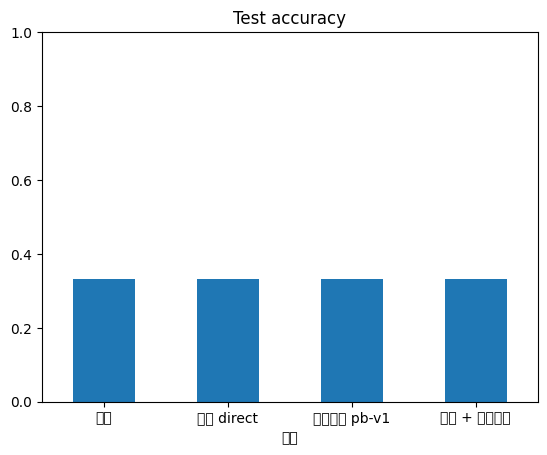

In [18]:
# =====================================================================
# Lab 7. 평가와 승인
# 무엇인가    : 학습에 쓰지 않은 테스트 과제로 개선 효과를 재고 나아진 경우에만 반영하는 단계임
# 왜 필요한가 : 학습 과제에서 점수가 올라도 처음 보는 과제에서 그대로면 진짜 나아진 것이 아님
#               금융에서는 검증 없이 바뀐 규칙이 배포되면 사고로 이어질 수 있음
#               그래서 평가를 통과한 변경만 승인하고 그 결정을 기록함
# =====================================================================

# [Lab 7-1] 네 가지 조건 비교: 기본 / 최고 전략 / 플레이북 / 둘 다
# 모든 조건은 같은 과제를 같은 횟수만큼 풂. 조건을 맞춰야 공정한 비교가 됨
# 실행 결과 : 조건별 정답률과 평균 도구 호출 수 표와 막대그래프가 나옴

def evaluate(label, strategy=None, playbook=None, repeats=2):
    """테스트 과제를 여러 번 풀게 하고 정답률과 평균 도구 호출 수를 냄.

    필요한 이유
        개선 전후를 같은 조건에서 비교해야 효과를 믿을 수 있음
        temperature를 낮춰(0.3) 운의 영향을 줄임
    """
    jobs = []
    for task in TEST:
        for _ in range(repeats):
            jobs.append({"task": task, "strategy": strategy, "playbook": playbook, "temperature": 0.3})
    trajectories = run_many(jobs)
    for traj in trajectories:
        compute_reward(traj, TASKS[traj["task_id"]])

    return {
        "조건": label,
        "정답률": np.mean([traj["correct"] for traj in trajectories]),
        "평균 도구 호출": np.mean([traj["tool_calls"] for traj in trajectories]),
    }


results = pd.DataFrame([
    evaluate("기본"),
    evaluate(f"전략 {best_strategy}", strategy=best_strategy),
    evaluate("플레이북 pb-v1", playbook=playbook),
    evaluate("전략 + 플레이북", strategy=best_strategy, playbook=playbook),
])
display(results.round(2))

results.set_index("조건")["정답률"].plot.bar(ylim=(0, 1), rot=0, title="Test accuracy")
plt.show()

In [19]:
# [Lab 7-2] 승인 게이트와 감사 로그
# 플레이북을 쓴 정답률이 기본보다 높을 때만 배포를 승인함
# 승인 여부도 감사 로그에 남겨서 플레이북이 언제 어떤 근거로 바뀌었는지 끝까지 추적할 수 있게 함
# 실행 결과 : 승인 또는 거절과 함께 플레이북의 모든 변경 이력이 표로 나옴

def accept_update(old_score, new_score, min_gain=0.0):
    """새 버전이 기존보다 min_gain 넘게 좋을 때만 True를 돌려줌.

    필요한 이유
        사람이 매번 판단하지 않아도 같은 기준으로 승인과 거절을 정할 수 있음
        min_gain을 0.05로 주면 5%p 넘게 올라야 승인하는 식으로 기준을 엄격하게 할 수 있음
    """
    return new_score - old_score > min_gain


scores = dict(zip(results["조건"], results["정답률"]))
base_score = scores["기본"]
playbook_score = scores["플레이북 pb-v1"]

approved = accept_update(base_score, playbook_score)
audit_log.append({
    "op": "GATE",
    "id": "pb-v1",
    "text": f"테스트 정답률 {base_score:.0%} → {playbook_score:.0%}",
    "reason": "승인" if approved else "거절 (성능 향상 없음)",
})

print("pb-v1 배포:", "승인" if approved else "거절")
pd.DataFrame(audit_log)

pb-v1 배포: 거절


,op,id,text,reason
0,ADD,R1,만기까지 보유한 경우에는 상품의 만기 조건에 따른 약정 이율로 세전 이자를 계산한 ...,"이자 계산은 먼저 상품의 만기 전/후 구간과 약정 이율을 확인한 뒤, 세전 이자를 ..."
1,MODIFY,R1,만기까지 보유한 경우에는 상품의 만기 조건에 따른 약정 이율로 세전 이자를 계산한 ...,"만기 보유의 세후 이자는 상품별 약정 이율과 세율을 함께 적용해 계산하며, 계산 순..."
2,GATE,pb-v1,테스트 정답률 33% → 33%,거절 (성능 향상 없음)


In [20]:
# [Lab 7-3] (선택) 검증기와 심사 모델의 판정 비교
# 정답을 아는 검증기와 정답을 모르는 심사 모델이 같은 답을 얼마나 다르게 판정하는지 셈
# 불일치율이 높으면 심사 모델만으로 보상을 주는 것은 위험함 (슬라이드 "보상 해킹 찾아내기")
# 실행 결과 : 판정 불일치율 한 줄이 나옴. 시간이 없으면 건너뛰어도 됨

samples = []
for trajectories in groups.values():
    samples.extend(trajectories)
samples = samples[:8]

disagreements = 0
for traj in samples:
    task = TASKS[traj["task_id"]]
    judge = rubric_judge(task["question"], traj["answer"], summarize_actions(traj))
    judge_passed = judge["score"] >= 7   # 심사 점수 7점 이상을 통과로 봄
    if traj["correct"] != judge_passed:
        disagreements += 1

print(f"검증기와 심사 모델의 판정 불일치율 {disagreements / len(samples):.0%}")

검증기와 심사 모델의 판정 불일치율 50%


## 부록. 가중치 학습으로 넘어가려면
오늘은 API 모델이라 가중치를 바꾸지 않고 플레이북(글)으로 정책을 개선했음. 가중치까지 바꾸려면 오픈 모델과 GPU가 필요함.
- Lab 4의 `rejection_sft.jsonl` → SFT로 도구 사용 형식을 먼저 익힘
- Lab 2의 `compute_reward()` → Hugging Face TRL `GRPOTrainer`의 보상 함수로 연결함
- 도구 결과 토큰은 모델이 만든 것이 아니므로 학습 때 손실 계산에서 뺌 (마스킹)

## 정리
| 단계 | 알려 주는 것 | 이 노트북에서 |
|---|---|---|
| 보상과 피드백 | 얼마나 잘했나 | Lab 2 `compute_reward()`, Lab 5 반성문 |
| 궤적 수집 | 무엇을 했나 | Lab 3 `trajectories.jsonl` |
| 궤적 최적화 | 무엇이 더 나았나 | Lab 4 `group_advantage()`, Best-of-N, 정책 경사 |
| 자기 개선 | 찾은 차이를 어디에 남기나 | Lab 6 플레이북 `apply_ops()` |
| 검증과 승인 | 정말 나아졌나 | Lab 7 `evaluate()`, `accept_update()` |

**생각해 볼 질문**
1. 플레이북에 생긴 규칙은 Lab 3에서 본 틀린 이유와 얼마나 맞아떨어지나?
2. 해킹 답변에 심사 모델이 속았다면 기준표를 어떻게 고쳐야 할까?
3. 플레이북이 거절되었다면 어떤 규칙이 문제였을까?